# 06 · Human-in-the-Loop  🟡 Intermediate

Agents shouldn't send emails or book flights without asking. LangGraph can **pause** a run, show something to a human,
and **resume** with their answer, even hours later, because state is saved by the checkpointer.

| Tool | Use |
|---|---|
| `interrupt(payload)` | pause inside a node / tool and return a value to the caller |
| `Command(resume=value)` | resume; `interrupt()` returns `value` |
| `interrupt_before=[...]` | static breakpoint before a node |
| `graph.update_state(...)` | edit the saved state before resuming |

⚠️ Interrupts require a **checkpointer** and a **thread_id**.

In [1]:
from helpers import get_llm, show_graph, print_messages

llm = get_llm()   # ChatAnthropic -> Claude, key read from CLAUDE_KEY in .env

## 1. Approve / edit / reject a draft

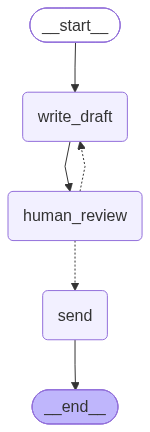

In [2]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

class EmailState(TypedDict):
    request: str
    draft: str
    status: str

def write_draft(state: EmailState):
    draft = llm.invoke(f"Write a short (max 60 words) professional email for this request:\n{state['request']}").text
    return {"draft": draft}

def human_review(state: EmailState) -> Command[Literal["send", "write_draft"]]:
    # ⏸️ Execution stops here. The payload is shown to the caller.
    decision = interrupt({"question": "Approve this email?", "draft": state["draft"]})
    # ▶️ When resumed, `decision` is whatever was passed in Command(resume=...)
    if decision["action"] == "approve":
        return Command(goto="send")
    if decision["action"] == "edit":
        return Command(update={"draft": decision["text"]}, goto="send")
    return Command(update={"request": state["request"] + f"\nReviewer feedback: {decision['feedback']}"},
                   goto="write_draft")

def send(state: EmailState):
    print("📧 SENT:\n", state["draft"])
    return {"status": "sent"}

b = StateGraph(EmailState)
b.add_node(write_draft); b.add_node(human_review); b.add_node(send)
b.add_edge(START, "write_draft")
b.add_edge("write_draft", "human_review")
b.add_edge("send", END)
email_graph = b.compile(checkpointer=InMemorySaver())
show_graph(email_graph)

In [3]:
config = {"configurable": {"thread_id": "email-1"}}
result = email_graph.invoke({"request": "Tell my manager I'll be 30 minutes late tomorrow due to a doctor's appointment."}, config)

pending = result["__interrupt__"][0].value
print(pending["question"], "\n\n", pending["draft"])
print("\nGraph is paused before:", email_graph.get_state(config).next)

Approve this email? 

 Subject: Late Arrival Tomorrow

Hi [Manager's Name],

I wanted to let you know that I'll be about 30 minutes late tomorrow because of a doctor's appointment. I expect to arrive by [time] and will make sure my work stays on track. Please let me know if anything needs my attention before then.

Thank you for understanding.

Best regards,
[Your Name]

Graph is paused before: ('human_review',)


The run is **paused and saved**. Now the human rejects it with feedback → the graph loops back to `write_draft`.
(In a real app this answer comes from a UI; here you could also use `input()`.)

In [4]:
result = email_graph.invoke(Command(resume={"action": "reject", "feedback": "Make it more casual and add that I'll make up the time."}), config)
print(result["__interrupt__"][0].value["draft"])

**Subject:** Running a bit late tomorrow

Hi [Manager's Name],

Just a heads-up that I'll be about 30 minutes late tomorrow because of a doctor's appointment. I'll make up the time by staying a little later. Let me know if that works!

Thanks,
[Your Name]


In [5]:
# Happy now -> approve
result = email_graph.invoke(Command(resume={"action": "approve"}), config)
print("status:", result["status"])

📧 SENT:
 **Subject:** Running a bit late tomorrow

Hi [Manager's Name],

Just a heads-up that I'll be about 30 minutes late tomorrow because of a doctor's appointment. I'll make up the time by staying a little later. Let me know if that works!

Thanks,
[Your Name]
status: sent


⚠️ **Important rule:** on resume, the interrupted node **re-runs from its beginning**; `interrupt()` then returns the resume value.
Keep code *before* `interrupt()` free of side effects (or idempotent).

## 2. Interrupt inside a tool: approve sensitive actions

In [6]:
from langchain_core.tools import tool
from langchain.agents import create_agent

@tool
def book_flight(destination: str, date: str) -> str:
    """Book a flight to a destination on a date (YYYY-MM-DD)."""
    answer = interrupt({"action": "book_flight", "destination": destination, "date": date,
                        "question": "Confirm booking? (yes/no)"})
    if answer == "yes":
        return f"✈️ Booked flight to {destination} on {date}. Confirmation #LG123."
    return "The user declined this booking. Do not book."

@tool
def search_flights(destination: str) -> str:
    """Search available flights to a destination."""
    return f"Flights to {destination}: 2026-11-02 ₹8,500 | 2026-11-03 ₹7,900"

travel_agent = create_agent(llm, tools=[search_flights, book_flight],
                            system_prompt="You are a travel agent. Book the cheapest flight the user asks for.",
                            checkpointer=InMemorySaver())

config = {"configurable": {"thread_id": "trip-1"}}
result = travel_agent.invoke({"messages": [("user", "Book me the cheapest flight to Goa next month.")]}, config)
print("⏸️ Agent wants approval:", result["__interrupt__"][0].value)

⏸️ Agent wants approval: {'action': 'book_flight', 'destination': 'Goa', 'date': '2026-11-03', 'question': 'Confirm booking? (yes/no)'}


In [7]:
result = travel_agent.invoke(Command(resume="yes"), config)
print(result["messages"][-1].text)

I booked your flight to Goa for **3 November 2026** at **₹7,900**. The confirmation number is **#LG123**.

The search only found two flights, both in November 2026, and this was the cheaper one. The other option was 2 November for ₹8,500. I took November to be the "next month" you meant. If you meant a different month, let me know and I'll look for other dates.


## 3. Static breakpoints + editing state

`interrupt_before=["send"]` pauses before a node without changing node code.
While paused, `update_state` can edit the state. Resume with `invoke(None, config)`.

In [8]:
b = StateGraph(EmailState)
b.add_node(write_draft); b.add_node(send)
b.add_edge(START, "write_draft"); b.add_edge("write_draft", "send"); b.add_edge("send", END)
bp_graph = b.compile(checkpointer=InMemorySaver(), interrupt_before=["send"])

config = {"configurable": {"thread_id": "email-2"}}
bp_graph.invoke({"request": "Invite the team to Friday's pizza lunch."}, config)
print("paused before:", bp_graph.get_state(config).next)

bp_graph.update_state(config, {"draft": "Hi team! 🍕 Pizza lunch this Friday at 1pm. See you there!"})
bp_graph.invoke(None, config)       # None = continue from the checkpoint

paused before: ('send',)
📧 SENT:
 Hi team! 🍕 Pizza lunch this Friday at 1pm. See you there!


{'request': "Invite the team to Friday's pizza lunch.",
 'draft': 'Hi team! 🍕 Pizza lunch this Friday at 1pm. See you there!',
 'status': 'sent'}

## ✅ Recap
* `interrupt(payload)` pauses; result contains `__interrupt__`; resume with `Command(resume=...)`.
* Interrupted nodes re-run from the top on resume → keep pre-interrupt code side-effect free.
* Put `interrupt()` inside tools to gate risky actions.
* `interrupt_before/after` + `update_state` = debugger-style breakpoints and state edits.